In [1]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy

STEP 1. Input Data
{'Membership': 1, 'Age': 35, 'Income': 5200, 'Purchase': 4}


STEP 2. Data Preprocessing
Basis Data
[1]

Angle Data
[0. 0. 0.]

Amplitude Data
[6.73061466e-03 9.99977035e-01 7.69213104e-04 1.92303276e-04]


STEP 3. Basis Encoding
        ┌───┐ ░ ┌─┐
     q: ┤ X ├─░─┤M├
        └───┘ ░ └╥┘
meas: 1/═════════╩═
                 0 


STEP 4. Angle Encoding
        ┌───────┐ ░ ┌─┐      
   q_0: ┤ Ry(0) ├─░─┤M├──────
        ├───────┤ ░ └╥┘┌─┐   
   q_1: ┤ Ry(0) ├─░──╫─┤M├───
        ├───────┤ ░  ║ └╥┘┌─┐
   q_2: ┤ Ry(0) ├─░──╫──╫─┤M├
        └───────┘ ░  ║  ║ └╥┘
meas: 3/═════════════╩══╩══╩═
                     0  1  2 


STEP 5. Amplitude Encoding
Statevector([6.73061466e-03+0.j, 9.99977035e-01+0.j, 7.69213104e-04+0.j,
             1.92303276e-04+0.j],
            dims=(2, 2))


STEP 6. Circuit Draw


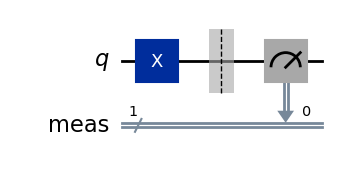

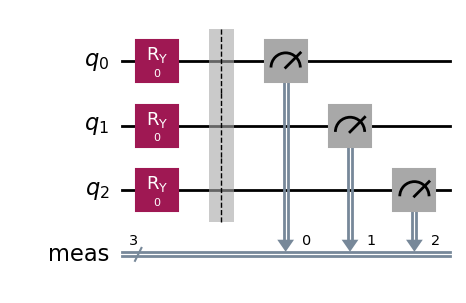



STEP 7. Statevector
Statevector([6.73061466e-03+0.j, 9.99977035e-01+0.j, 7.69213104e-04+0.j,
             1.92303276e-04+0.j],
            dims=(2, 2))


STEP 8. Circuit Metrics
Basis
Depth : 2
Gate : 2

Angle
Depth : 2
Gate : 6


STEP 9. Transpile
Basis Depth : 2
Angle Depth : 1


STEP 10. Sensitivity Test
     ┌─────────┐ 
q_0: ┤ Ry(π/5) ├─
     ├─────────┴┐
q_1: ┤ Ry(2π/5) ├
     ├──────────┤
q_2: ┤ Ry(4π/5) ├
     └──────────┘


STEP 11. Practical Analysis
Basis
- Binary Data

Angle
- General QML

Amplitude
- Research


STEP 12. Final Comparison
Item           Basis          Angle          Amplitude      
------------------------------------------------------------
Data           Binary         Real           Vector         
Expression     Low            High           Very High      
Circuit        Easy           Easy           Hard           
QML            Low            Very High      Research       

Recommended Encoding
★★★★★ Angle Encoding


In [5]:
"""
===========================================================
Encoding Comparison

Basis Encoding
Angle Encoding
Amplitude Encoding

===========================================================
"""

import numpy as np

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from qiskit_aer import AerSimulator
from qiskit import transpile

from sklearn.preprocessing import MinMaxScaler

import matplotlib.pyplot as plt

# =====================================================
# STEP 1
# Input Data
# =====================================================

print("=" * 60)
print("STEP 1. Input Data")
print("=" * 60)

customer = {

    "Membership":1,
    "Age":35,
    "Income":5200,
    "Purchase":4

}

print(customer)

# =====================================================
# STEP 2
# Data Preprocessing
# =====================================================

print("\n")
print("=" * 60)
print("STEP 2. Data Preprocessing")
print("=" * 60)

# Basis
basis_data = [
    customer["Membership"]
]

print("Basis Data")
print(basis_data)

# Angle

X = np.array([
    [
        customer["Age"],
        customer["Income"],
        customer["Purchase"]
    ]
])

scaler = MinMaxScaler()

angle = scaler.fit_transform(X)

angle = angle.flatten()

print("\nAngle Data")
print(angle)

# Amplitude

amp = np.array([
    customer["Age"],
    customer["Income"],
    customer["Purchase"],
    1
])

amp = amp / np.linalg.norm(amp)

print("\nAmplitude Data")

print(amp)

# =====================================================
# STEP 3
# Basis Encoding
# =====================================================

print("\n")
print("=" * 60)
print("STEP 3. Basis Encoding")
print("=" * 60)

qc_basis = QuantumCircuit(1)

if basis_data[0]==1:
    qc_basis.x(0)

qc_basis.measure_all()

print(qc_basis)

# =====================================================
# STEP 4
# Angle Encoding
# =====================================================

print("\n")
print("=" * 60)
print("STEP 4. Angle Encoding")
print("=" * 60)

qc_angle = QuantumCircuit(3)

for i,v in enumerate(angle):

    qc_angle.ry(v*np.pi,i)

qc_angle.measure_all()

print(qc_angle)

# =====================================================
# STEP 5
# Amplitude Encoding
# =====================================================

print("\n")
print("=" * 60)
print("STEP 5. Amplitude Encoding")
print("=" * 60)

state = Statevector(amp)

print(state)

# =====================================================
# STEP 6
# Circuit Draw
# =====================================================

print("\n")
print("=" * 60)
print("STEP 6. Circuit Draw")
print("=" * 60)

fig1 = qc_basis.draw("mpl")

fig2 = qc_angle.draw("mpl")

display(qc_basis.draw("mpl"))
display(qc_angle.draw("mpl"))

# =====================================================
# STEP 7
# Statevector
# =====================================================

print("\n")
print("=" * 60)
print("STEP 7. Statevector")
print("=" * 60)

print(state.draw())

# =====================================================
# STEP 8
# Circuit Metrics
# =====================================================

print("\n")
print("=" * 60)
print("STEP 8. Circuit Metrics")
print("=" * 60)

print("Basis")

print("Depth :",qc_basis.depth())

print("Gate :",qc_basis.size())

print()

print("Angle")

print("Depth :",qc_angle.depth())

print("Gate :",qc_angle.size())

# =====================================================
# STEP 9
# Transpile
# =====================================================

print("\n")
print("=" * 60)
print("STEP 9. Transpile")
print("=" * 60)

backend = AerSimulator()

tb = transpile(qc_basis,backend)

ta = transpile(qc_angle,backend)

print("Basis Depth :",tb.depth())

print("Angle Depth :",ta.depth())

# =====================================================
# STEP 10
# Sensitivity Test
# =====================================================

print("\n")
print("=" * 60)
print("STEP 10. Sensitivity Test")
print("=" * 60)

test = np.array([
    0.2,
    0.4,
    0.8
])

qc_test = QuantumCircuit(3)

for i,v in enumerate(test):

    qc_test.ry(v*np.pi,i)

print(qc_test)

# =====================================================
# STEP 11
# Practical Analysis
# =====================================================

print("\n")
print("=" * 60)
print("STEP 11. Practical Analysis")
print("=" * 60)

print("Basis")
print("- Binary Data")

print()

print("Angle")
print("- General QML")

print()

print("Amplitude")
print("- Research")

# =====================================================
# STEP 12
# Final Comparison
# =====================================================

print("\n")
print("=" * 60)
print("STEP 12. Final Comparison")
print("=" * 60)

print("{:<15}{:<15}{:<15}{:<15}".format(
    "Item",
    "Basis",
    "Angle",
    "Amplitude"
))

print("-"*60)

print("{:<15}{:<15}{:<15}{:<15}".format(
    "Data",
    "Binary",
    "Real",
    "Vector"
))

print("{:<15}{:<15}{:<15}{:<15}".format(
    "Expression",
    "Low",
    "High",
    "Very High"
))

print("{:<15}{:<15}{:<15}{:<15}".format(
    "Circuit",
    "Easy",
    "Easy",
    "Hard"
))

print("{:<15}{:<15}{:<15}{:<15}".format(
    "QML",
    "Low",
    "Very High",
    "Research"
))

print()

print("Recommended Encoding")

print("★★★★★ Angle Encoding")